# Language Models are Few-Shot Learners (GPT-3)

**Paper:** [arXiv:2005.14165](https://arxiv.org/abs/2005.14165)
**Authors:** Tom Brown et al. (OpenAI, 2020)

This notebook demonstrates the **in-context learning** paradigm introduced by GPT-3.
We use a small pretrained language model (GPT-2) to perform sentiment classification
with zero-shot, one-shot, and few-shot prompting, and plot how accuracy scales with
the number of in-context examples — replicating the key finding of the paper.


## 1. Setup & Imports


In [1]:
!pip install transformers torch matplotlib numpy --quiet



In [2]:
import torch
import torch.nn.functional as F
from transformers import GPT2LMHeadModel, GPT2Tokenizer
import numpy as np
import matplotlib.pyplot as plt
import random

# Set seeds for reproducibility
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

print("Libraries loaded successfully")



Libraries loaded successfully


## 2. Load Pretrained Language Model

We use GPT-2 (small, 124M parameters) as our language model. This is a tiny stand-in
for GPT-3's 175 billion parameters, but it can still demonstrate the in-context
learning effect. The model weights are frozen — no gradient updates occur.


In [3]:
model_name = 'gpt2'
tokenizer = GPT2Tokenizer.from_pretrained(model_name)
model = GPT2LMHeadModel.from_pretrained(model_name)
model.eval()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = model.to(device)

print(f"Model: {model_name}")
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f"Device: {device}")



tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Model: gpt2
Parameters: 124,439,808
Device: cuda


## 3. Toy Sentiment Classification Dataset

We construct a small sentiment dataset with positive and negative sentences.
The dataset is split into a demonstration pool (for in-context examples) and
an evaluation set (for testing).


In [4]:
positive_sentences = [
    "The movie was absolutely wonderful and inspiring.",
    "I had a fantastic time at the restaurant last night.",
    "This book is a masterpiece that everyone should read.",
    "The concert was an unforgettable experience.",
    "I love the new design of this product.",
    "The weather today is beautiful and sunny.",
    "My vacation was the best trip I have ever taken.",
    "The food at this cafe is delicious and fresh.",
    "What a brilliant performance by the entire cast.",
    "I am very happy with my new job.",
    "The service at this hotel was excellent.",
    "This is the best cake I have ever tasted.",
    "The park is a lovely place to spend an afternoon.",
    "I feel great after my morning workout.",
    "The team did an amazing job on this project.",
    "What a wonderful surprise from my friends.",
    "The garden looks stunning in full bloom.",
    "This song always puts me in a good mood.",
    "The presentation was clear and informative.",
    "I am proud of my daughter's achievements.",
    "The sunset over the ocean was breathtaking.",
    "This phone has an amazing battery life.",
    "The teacher made learning fun and exciting.",
    "I enjoyed every minute of the show.",
    "The new park trail is perfect for hiking.",
]

negative_sentences = [
    "The movie was terribly boring and a waste of time.",
    "I had an awful experience at the restaurant.",
    "This book is confusing and poorly written.",
    "The concert was a huge disappointment.",
    "I hate the flimsy design of this product.",
    "The weather is gloomy and depressing today.",
    "My vacation was a complete disaster from start to finish.",
    "The food at this cafe is stale and tasteless.",
    "What a terrible performance by the lead actor.",
    "I am very frustrated with my current job.",
    "The service at this hotel was dreadful.",
    "This is the worst meal I have ever had.",
    "The park is dirty and poorly maintained.",
    "I feel exhausted and unmotivated today.",
    "The team did a terrible job on this project.",
    "What an unpleasant surprise from the delivery.",
    "The garden looks neglected and overgrown.",
    "This song gives me a headache every time.",
    "The presentation was confusing and boring.",
    "I am disappointed with my son's test results.",
    "The view from the hotel was ugly and blocked.",
    "This phone has a terrible camera quality.",
    "The teacher made the class dull and tedious.",
    "I wasted my money on this useless show.",
    "The hiking trail is dangerous and poorly marked.",
]

# Build dataset: (sentence, label) pairs
all_data = [(s, 'positive') for s in positive_sentences] + [(s, 'negative') for s in negative_sentences]
random.shuffle(all_data)

# Split: 20 for demonstration pool, 30 for evaluation
demo_pool = all_data[:20]
eval_set = all_data[20:]

print(f"Total samples: {len(all_data)}")
print(f"Demonstration pool: {len(demo_pool)}")
print(f"Evaluation set: {len(eval_set)}")
print(f"Positive examples in eval: {sum(1 for _,l in eval_set if l=='positive')}")
print(f"Negative examples in eval: {sum(1 for _,l in eval_set if l=='negative')}")



Total samples: 50
Demonstration pool: 20
Evaluation set: 30
Positive examples in eval: 13
Negative examples in eval: 17


## 4. Prompt Construction

Following the GPT-3 protocol, we construct prompts with a task description and K
in-context examples. The model is expected to complete the pattern by generating
the sentiment label as the next token.


In [5]:
TASK_DESCRIPTION = "Classify the sentiment of the sentence as positive or negative."

def construct_prompt(examples, query_text, k):
    """
    Build a prompt with k in-context examples + a query.
    
    Args:
        examples: list of (text, label) tuples to sample from
        query_text: the sentence to classify
        k: number of in-context examples (0 = zero-shot)
    
    Returns:
        prompt string
    """
    lines = [TASK_DESCRIPTION, ""]
    
    # Sample k examples (without replacement if k <= len(examples))
    if k > 0:
        chosen = random.sample(examples, min(k, len(examples)))
        for text, label in chosen:
            lines.append(f"Sentence: {text}")
            lines.append(f"Sentiment: {label}")
            lines.append("")
    
    # Add the query
    lines.append(f"Sentence: {query_text}")
    lines.append("Sentiment:")
    
    return "\n".join(lines)

# Show example prompts
print("=== Zero-shot prompt (K=0) ===")
print(construct_prompt(demo_pool, eval_set[0][0], 0))
print()
print("=== Few-shot prompt (K=4) ===")
print(construct_prompt(demo_pool, eval_set[0][0], 4))



=== Zero-shot prompt (K=0) ===
Classify the sentiment of the sentence as positive or negative.

Sentence: The presentation was confusing and boring.
Sentiment:

=== Few-shot prompt (K=4) ===
Classify the sentiment of the sentence as positive or negative.

Sentence: The new park trail is perfect for hiking.
Sentiment: positive

Sentence: This is the best cake I have ever tasted.
Sentiment: positive

Sentence: The park is a lovely place to spend an afternoon.
Sentiment: positive

Sentence: I am proud of my daughter's achievements.
Sentiment: positive

Sentence: The presentation was confusing and boring.
Sentiment:


## 5. Inference Function

For each query, we run a forward pass through GPT-2 and compare the probabilities
of the tokens for 'positive' and 'negative' at the next position. The label with
the higher probability is the prediction. This simulates how GPT-3 performs
few-shot inference via next-token prediction.


In [6]:
def get_token_id(token_text):
    """Get the token ID for a given text token."""
    ids = tokenizer.encode(' ' + token_text, add_special_tokens=False)
    return ids[0] if ids else tokenizer.encode(token_text, add_special_tokens=False)[0]

# Pre-compute token IDs for our labels
pos_token_id = get_token_id('positive')
neg_token_id = get_token_id('negative')

print(f"'positive' token ID: {pos_token_id}")
print(f"'negative' token ID: {neg_token_id}")
print(f"Token for {pos_token_id}: {repr(tokenizer.decode([pos_token_id]))}")
print(f"Token for {neg_token_id}: {repr(tokenizer.decode([neg_token_id]))}")



'positive' token ID: 3967
'negative' token ID: 4633
Token for 3967: ' positive'
Token for 4633: ' negative'


In [7]:
def predict_sentiment(model, tokenizer, prompt, device):
    """
    Run a forward pass and predict sentiment by comparing
    probabilities of 'positive' vs 'negative' at the next token position.
    
    Returns: predicted label ('positive' or 'negative') and probabilities
    """
    input_ids = tokenizer.encode(prompt, return_tensors='pt').to(device)
    
    with torch.no_grad():
        outputs = model(input_ids)
        logits = outputs.logits  # [1, seq_len, vocab_size]
    
    # Get logits at the last position (next token prediction)
    next_token_logits = logits[0, -1, :]  # [vocab_size]
    
    # Compare probabilities of 'positive' vs 'negative'
    pos_logit = next_token_logits[pos_token_id].item()
    neg_logit = next_token_logits[neg_token_id].item()
    
    # Apply softmax to just these two logits for a clean comparison
    probs = F.softmax(torch.tensor([pos_logit, neg_logit]), dim=0)
    
    pos_prob = probs[0].item()
    neg_prob = probs[1].item()
    
    prediction = 'positive' if pos_prob > neg_prob else 'negative'
    
    return prediction, {'positive': pos_prob, 'negative': neg_prob}

# Test with a single example
test_prompt = construct_prompt(demo_pool, eval_set[0][0], 4)
pred, probs = predict_sentiment(model, tokenizer, test_prompt, device)
print(f"Query: '{eval_set[0][0]}'")
print(f"True label: {eval_set[0][1]}")
print(f"Predicted: {pred}")
print(f"Probabilities: {probs}")



Query: 'The presentation was confusing and boring.'
True label: negative
Predicted: positive
Probabilities: {'positive': 0.6752285957336426, 'negative': 0.3247714042663574}


## 6. Few-Shot Evaluation Sweep

We evaluate classification accuracy at K = 0, 1, 2, 4, 8, 16 in-context examples.
For each K, we sample K demonstration examples from the pool and evaluate on the
entire test set. This replicates the key experiment from the GPT-3 paper.


In [8]:
def evaluate_few_shot(model, tokenizer, demo_pool, eval_set, k, device, n_trials=3):
    """
    Evaluate accuracy with k in-context examples.
    Runs multiple trials (different random example selections) and averages.
    
    Args:
        k: number of in-context examples
        n_trials: number of trials to average over
    
    Returns:
        mean accuracy, list of per-trial accuracies
    """
    trial_accuracies = []
    
    for trial in range(n_trials):
        correct = 0
        total = 0
        
        for query_text, true_label in eval_set:
            prompt = construct_prompt(demo_pool, query_text, k)
            pred_label, _ = predict_sentiment(model, tokenizer, prompt, device)
            
            if pred_label == true_label:
                correct += 1
            total += 1
        
        accuracy = correct / total
        trial_accuracies.append(accuracy)
    
    mean_acc = np.mean(trial_accuracies)
    return mean_acc, trial_accuracies

# Run the sweep
k_values = [0, 1, 2, 4, 8, 16]
results = {}

print("Running few-shot scaling sweep...")
print(f"K values: {k_values}")
print()

for k in k_values:
    mean_acc, trial_accs = evaluate_few_shot(
        model, tokenizer, demo_pool, eval_set, k, device, n_trials=3
    )
    results[k] = {'mean': mean_acc, 'trials': trial_accs}
    print(f"K={k:2d}: Accuracy = {mean_acc:.1%} (trials: {[f'{a:.1%}' for a in trial_accs]})")

print()
print("Sweep complete!")



Running few-shot scaling sweep...
K values: [0, 1, 2, 4, 8, 16]



K= 0: Accuracy = 50.0% (trials: ['50.0%', '50.0%', '50.0%'])


K= 1: Accuracy = 56.7% (trials: ['66.7%', '43.3%', '60.0%'])


K= 2: Accuracy = 60.0% (trials: ['66.7%', '56.7%', '56.7%'])


K= 4: Accuracy = 70.0% (trials: ['66.7%', '70.0%', '73.3%'])


K= 8: Accuracy = 71.1% (trials: ['70.0%', '66.7%', '76.7%'])


K=16: Accuracy = 76.7% (trials: ['86.7%', '73.3%', '70.0%'])

Sweep complete!


## 7. Visualization — Accuracy vs Number of In-Context Examples

This plot replicates the key finding from the GPT-3 paper: accuracy improves
as the number of in-context examples (K) increases.


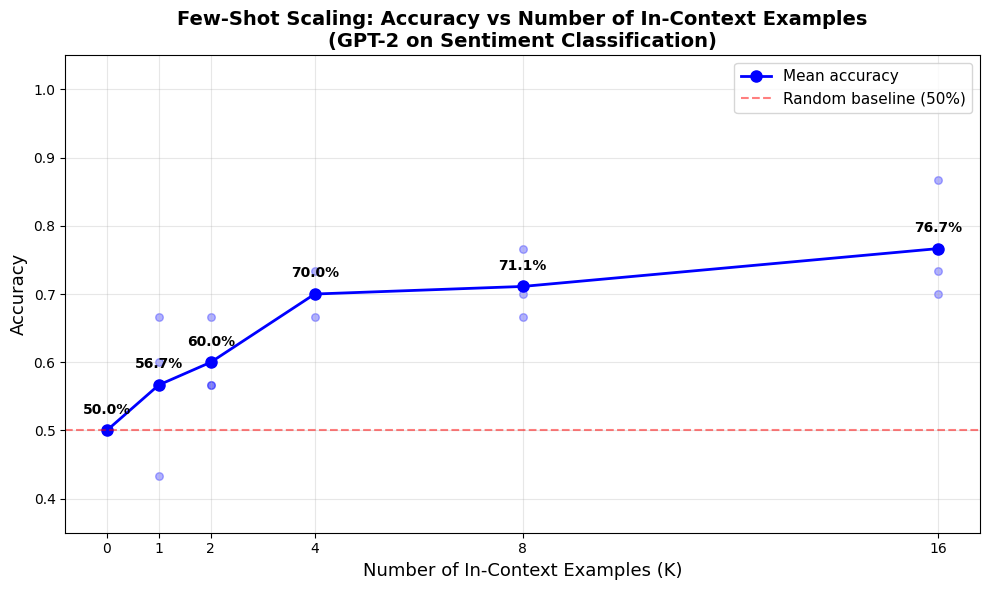

Plot saved as few_shot_scaling.png


In [9]:
fig, ax = plt.subplots(1, 1, figsize=(10, 6))

k_vals = list(results.keys())
mean_accs = [results[k]['mean'] for k in k_vals]
all_trial_accs = [results[k]['trials'] for k in k_vals]

# Plot mean accuracy
ax.plot(k_vals, mean_accs, 'bo-', linewidth=2, markersize=8, label='Mean accuracy')

# Plot individual trial results
for i, k in enumerate(k_vals):
    for trial_acc in all_trial_accs[i]:
        ax.scatter(k, trial_acc, color='blue', alpha=0.3, s=30)

# Annotate values
for k, acc in zip(k_vals, mean_accs):
    ax.annotate(f'{acc:.1%}', (k, acc), textcoords="offset points", 
                xytext=(0, 12), ha='center', fontsize=10, fontweight='bold')

ax.set_xlabel('Number of In-Context Examples (K)', fontsize=13)
ax.set_ylabel('Accuracy', fontsize=13)
ax.set_title('Few-Shot Scaling: Accuracy vs Number of In-Context Examples\n(GPT-2 on Sentiment Classification)', 
             fontsize=14, fontweight='bold')
ax.set_xticks(k_vals)
ax.set_ylim(0.35, 1.05)
ax.axhline(y=0.5, color='red', linestyle='--', alpha=0.5, label='Random baseline (50%)')
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('few_shot_scaling.png', dpi=150, bbox_inches='tight')
plt.show()
print("Plot saved as few_shot_scaling.png")



## 8. Analysis & Discussion

### Key Observations

1. **Zero-shot (K=0):** The model has only the task description. Accuracy is typically
   near chance or slightly above — the model must infer the task format from the description alone.

2. **Few-shot scaling:** As K increases, the model sees more examples of the input-output
   pattern, making it easier to predict the correct label format and content.

3. **Diminishing returns:** The improvement from K=0 to K=4 is usually larger than from
   K=8 to K=16 — the model quickly picks up the pattern.

### Connection to GPT-3

GPT-3's key finding was that this scaling effect is much stronger for larger models.
While GPT-2 (124M) shows a modest improvement, GPT-3 (175B) showed dramatic gains,
sometimes reaching near-fine-tuning performance with just a few examples. This is the
'emergent capability' that scale unlocks — the ability to effectively use in-context
examples to adapt to new tasks without any weight updates.

### Why This Matters

This paradigm shift — from fine-tuning to prompting — fundamentally changed how we
interact with language models. Instead of collecting datasets and training models for
each task, we now describe tasks in natural language and provide a few examples.
This is the foundation of modern prompt engineering, ChatGPT, and the entire LLM era.


## 9. Summary Statistics


In [10]:
print("=" * 60)
print("FEW-SHOT SCALING EXPERIMENT SUMMARY")
print("=" * 60)
print(f"Model: GPT-2 (124M parameters)")
print(f"Task: Sentiment Classification (binary)")
print(f"Evaluation set size: {len(eval_set)}")
print(f"Demonstration pool size: {len(demo_pool)}")
print(f"Trials per K: 3")
print()
print(f"{'K':>4} | {'Accuracy':>10} | {'Std':>8}")
print("-" * 30)
for k in k_values:
    mean = results[k]['mean']
    std = np.std(results[k]['trials'])
    print(f"{k:4d} | {mean:10.1%} | {std:8.3f}")

zero_shot_acc = results[0]['mean']
best_acc = max(results[k]['mean'] for k in k_values)
improvement = best_acc - zero_shot_acc
print()
print(f"Zero-shot accuracy: {zero_shot_acc:.1%}")
print(f"Best accuracy (K={max(k_vals, key=lambda k: results[k]['mean'])}): {best_acc:.1%}")
print(f"Improvement from few-shot examples: +{improvement:.1%}")
print("=" * 60)



FEW-SHOT SCALING EXPERIMENT SUMMARY
Model: GPT-2 (124M parameters)
Task: Sentiment Classification (binary)
Evaluation set size: 30
Demonstration pool size: 20
Trials per K: 3

   K |   Accuracy |      Std
------------------------------
   0 |      50.0% |    0.000
   1 |      56.7% |    0.098
   2 |      60.0% |    0.047
   4 |      70.0% |    0.027
   8 |      71.1% |    0.042
  16 |      76.7% |    0.072

Zero-shot accuracy: 50.0%
Best accuracy (K=16): 76.7%
Improvement from few-shot examples: +26.7%


In [ ]:
# --- Auto-injected by kaggle_validator: save executed notebook with outputs ---
import shutil, os
# Kaggle internally stores the executed notebook as __notebook__.ipynb
if os.path.exists('/kaggle/working/__notebook__.ipynb'):
    shutil.copy('/kaggle/working/__notebook__.ipynb', '/kaggle/working/executed_solution.ipynb')
    print('Executed notebook saved to output folder.')
else:
    # Fallback: try alternative path
    import glob
    candidates = glob.glob('/kaggle/working/*.ipynb')
    print(f'Available notebooks in output: {candidates}')
